In [186]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
%matplotlib inline

In [187]:
#read all the names
words = open("names.txt", "r").read().splitlines()

# build the vocab of chars and mappings from str to int/ int to str
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

# build the dataset
block_size = 3
X, Y = [], [] #x's are the inputs, y's are the labels to the nn

for w in words:
    context = [0] * block_size
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)



In [188]:
# now let's split the dataset into train, dev, test
# (cells are not in chrnological order anymore lol)

def build_dataset(words):
    block_size = 3
    X, Y = [], [] #x's are the inputs, y's are the labels to the nn

    for w in words:
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random # shuffle all the words
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [256]:
# constructing the neural net

C = torch.randn(27,10) # two dimensional lookup table
emb = C[X]

W1 = torch.randn(30, 150) * (5/3)/((10*block_size)**0.5) # 6 is the no of inputs to each hidden neuron. 3 context characters x embedded as 2 numbers
b1 = torch.randn(150) * 0.01 # 100 is no of hidden neurons

#multipled w1 and b1 with 0.1 and 0.01 to solve tanh creating dead neurons issue

# used Kaiming init (initialization) for W1!!!!


In [257]:
# setting up the parameters

# torch.cat((emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]), 1) # concatenate the tensors
# this is ok but wouldn't generalize when we do 3+ words so we use:
# torch.cat(torch.unbind(emb, 1), 1)
# but ! this view operation is much more efficient in pytorch:
# emb.view(32, 6) # is the same, view doesn’t copy or move any data so more efficient

h = torch.tanh(emb.view(-1,30) @ W1 + b1)
# h --> hidden layer of activations[32, 100]
W2 = torch.randn(150, 27) * 0.1
b2 = torch.randn(27) * 0.01 # fixing bad initialization

logits = h @ W2 + b2
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)

#loss = -prob[torch.arange(32), Y].log().mean()
#loss

parameters = [C, W1, b1, W2, b2]
sum(p.nelement() for p in parameters)

8997

In [191]:
# since many people do classification, and cross-entropy: there's a function
# in pytorch exactly for this!

#F.cross_entropy(logits, Y) # very easy! no logits+counts+prob+loss anymore
#F.cross_entropy(logits, Y) == loss # also more efficient --> no intermediate tensors
# fused kernels? many operations combined in a single kernel, so cahcing makes things faster!
# expressions take simpler mathematical forms + numberically more well-behaved.
# this is bc pytorch will substract the greatest number so we don't get infinity in .exp! nice

In [192]:
lre =  torch.linspace(-3, 0, 1000) #learning rate exponent
lrs = 10**lre # learning rate space


In [267]:
stepi = []
lossi = []

# cleaned up version
for p in parameters:
    p.requires_grad = True

for i in range(80000):

    #minibatch construction: bc using all training set all the time is inefficient
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    print(loss)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    #update
    lr = 0.01 # learning rate decay near the end of training
    # lr = lrs[i] # so we can try different learning rates to find the best!
    for p in parameters:
        p.data += -lr * p.grad

    #track stats
    # lri.append(lr)
    # lossi.append(loss.item())
    # we found the best lr to be 0.1 so we'll just roll w that
    stepi.append(i)
    lossi.append(loss.item())



tensor(1.9115, grad_fn=<NllLossBackward0>)
tensor(1.8164, grad_fn=<NllLossBackward0>)
tensor(2.3632, grad_fn=<NllLossBackward0>)
tensor(1.9878, grad_fn=<NllLossBackward0>)
tensor(2.0821, grad_fn=<NllLossBackward0>)
tensor(1.9880, grad_fn=<NllLossBackward0>)
tensor(2.0802, grad_fn=<NllLossBackward0>)
tensor(2.1439, grad_fn=<NllLossBackward0>)
tensor(1.8930, grad_fn=<NllLossBackward0>)
tensor(2.3027, grad_fn=<NllLossBackward0>)
tensor(1.6584, grad_fn=<NllLossBackward0>)
tensor(1.9430, grad_fn=<NllLossBackward0>)
tensor(1.9091, grad_fn=<NllLossBackward0>)
tensor(2.0899, grad_fn=<NllLossBackward0>)
tensor(2.0447, grad_fn=<NllLossBackward0>)
tensor(1.9280, grad_fn=<NllLossBackward0>)
tensor(1.7774, grad_fn=<NllLossBackward0>)
tensor(2.3215, grad_fn=<NllLossBackward0>)
tensor(2.0424, grad_fn=<NllLossBackward0>)
tensor(2.1115, grad_fn=<NllLossBackward0>)
tensor(2.2628, grad_fn=<NllLossBackward0>)
tensor(2.5172, grad_fn=<NllLossBackward0>)
tensor(1.8400, grad_fn=<NllLossBackward0>)
tensor(2.40

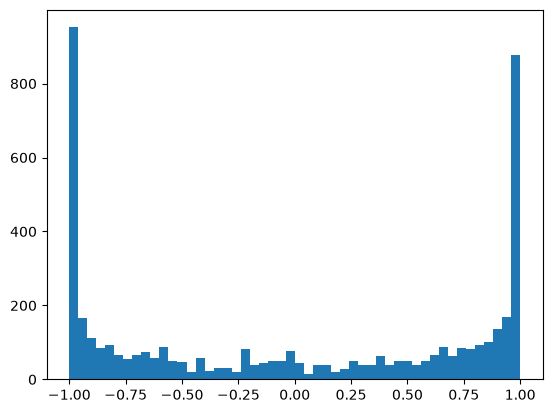

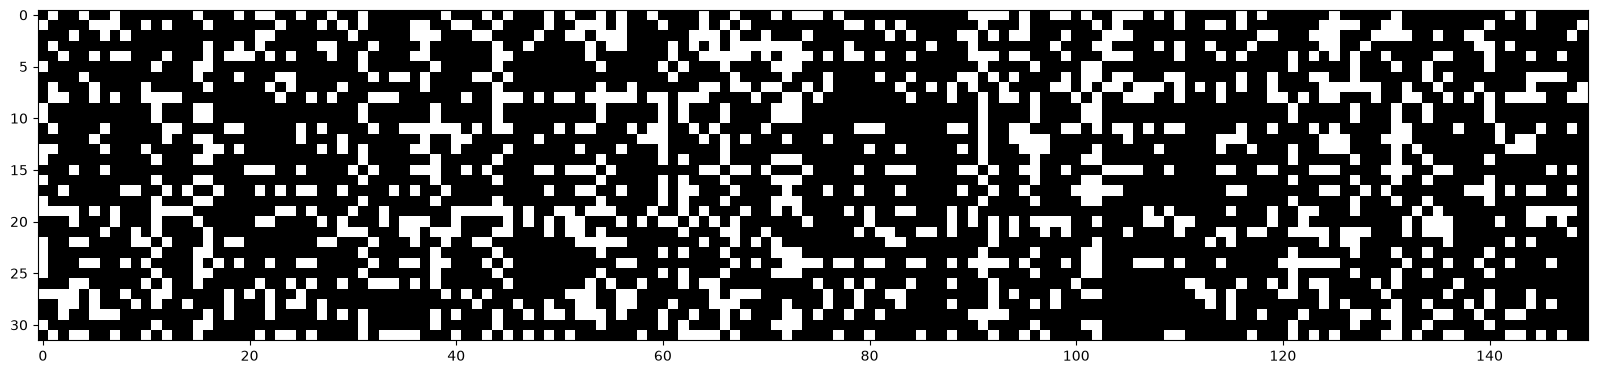

In [268]:
plt.hist(h.view(-1).tolist(), 50); # most values became -1 or 1 --> tanh is very active
plt.figure(figsize=(20, 10))
plt.imshow(h.abs()>0.99, cmap = 'gray', interpolation='nearest' )

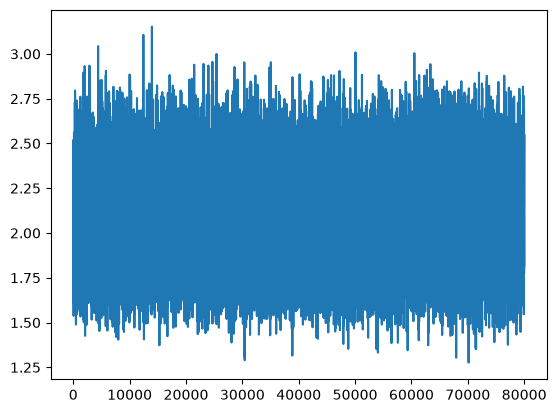

In [269]:
# plt.plot(lri, lossi)
plt.plot(stepi, lossi)

In [270]:
# above print statement prints the loss for the current batch. below is the total:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
print(loss)

emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print(loss) #if dev loss = training loss --> underfitting, model is too tiny


tensor(2.0860, grad_fn=<NllLossBackward0>)
tensor(2.1312, grad_fn=<NllLossBackward0>)


In [271]:
#training split, dev/validation split, test split
# 80%, 10%, 10%
# used to train the params, to train the hyperparams, to eval loss

print(Xtr.shape, Xdev.shape, Xtest.shape)

torch.Size([182625, 3]) torch.Size([22655, 3]) torch.Size([22866, 3])


In [272]:
# sampling from the model

g = torch.Generator().manual_seed(211231231)

for i in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1,-1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

nor.
salle.
jaceponte.
maxen.
ailylyn.
micherris.
jori.
elie.
ory.
mardyn.
xaz.
sayna.
eva.
macse.
domia.
roanidi.
plyndchival.
rymahaelen.
likiana.
hadustzelynn.
